# 01 · EDA of the bronze layer

Phase 1 exit check: what did ingestion actually collect? Volumes per source and day, HTTP
statuses, how many distinct vacancies there are, and **how many of them state a salary**.

Reads only `data/bronze` (set `BRONZE_DIR` to point elsewhere). Re-run after more days accumulate.

> The salary signals below are **provisional heuristics** on raw HTML. The real salary parser
> belongs to phase 2 (silver); this notebook only answers "is there enough salary data to bother".

In [1]:
import json
import os
import re
from pathlib import Path

import duckdb
import matplotlib.pyplot as plt
from selectolax.lexbor import LexborHTMLParser

BRONZE = Path(os.environ.get("BRONZE_DIR", "data/bronze"))
con = duckdb.connect()
plt.rcParams.update(
    {"figure.figsize": (7, 3.2), "axes.spines.top": False, "axes.spines.right": False}
)
print("bronze:", BRONZE)

bronze: data/bronze


## 1. Everything in bronze, from the meta files

In [2]:
# Meta files are tiny; reading them in Python avoids DuckDB's large per-file JSON buffers.
records = []
for meta_path in sorted(BRONZE.glob("*/dt=*/*.meta.json")):
    meta = json.loads(meta_path.read_text(encoding="utf-8"))
    source = meta_path.parent.parent.name
    url = meta["url"]
    if (source == "dou" and re.search(r"/companies/[^/]+/vacancies/[0-9]+/", url)) or (
        source == "djinni" and re.search(r"/jobs/[0-9]+-", url)
    ):
        kind = "vacancy"
    elif source in ("dou", "djinni"):
        kind = "listing"
    else:
        kind = "reference"
    records.append(
        (
            source,
            meta_path.parent.name.removeprefix("dt="),
            url,
            meta["status"],
            meta["bytes"],
            str(meta_path.parent / meta["file"]),
            kind,
        )
    )

con.execute(
    "CREATE TABLE pages (source VARCHAR, dt DATE, url VARCHAR, status INTEGER, bytes BIGINT, path VARCHAR, kind VARCHAR)"
)
con.executemany("INSERT INTO pages VALUES (?, ?, ?, ?, ?, ?, ?)", records)
con.sql(
    "SELECT count(*) AS files, count(DISTINCT source) AS sources, min(dt) AS first_day, max(dt) AS last_day FROM pages"
).show()

┌───────┬─────────┬────────────┬────────────┐
│ files │ sources │ first_day  │  last_day  │
│ int64 │  int64  │    date    │    date    │
├───────┼─────────┼────────────┼────────────┤
│   549 │       4 │ 2026-11-05 │ 2026-11-06 │
└───────┴─────────┴────────────┴────────────┘



In [3]:
con.sql("""
SELECT source, dt, count(*) AS pages, round(sum(bytes) / 1e6, 1) AS mb
FROM pages GROUP BY ALL ORDER BY source, dt
""").show()
con.sql(
    "SELECT source, status, count(*) AS pages FROM pages GROUP BY ALL ORDER BY source, status"
).show()

┌──────────────┬────────────┬───────┬────────┐
│    source    │     dt     │ pages │   mb   │
│   varchar    │    date    │ int64 │ double │
├──────────────┼────────────┼───────┼────────┤
│ djinni       │ 2026-11-06 │   225 │   14.9 │
│ dou          │ 2026-11-06 │   287 │    9.3 │
│ dou_salaries │ 2026-11-06 │    35 │  104.8 │
│ nbu_rates    │ 2026-11-05 │     1 │    0.0 │
│ nbu_rates    │ 2026-11-06 │     1 │    0.0 │
└──────────────┴────────────┴───────┴────────┘

┌──────────────┬────────┬───────┐
│    source    │ status │ pages │
│   varchar    │ int32  │ int64 │
├──────────────┼────────┼───────┤
│ djinni       │    200 │   225 │
│ dou          │    200 │   287 │
│ dou_salaries │    200 │    35 │
│ nbu_rates    │    200 │     2 │
└──────────────┴────────┴───────┘



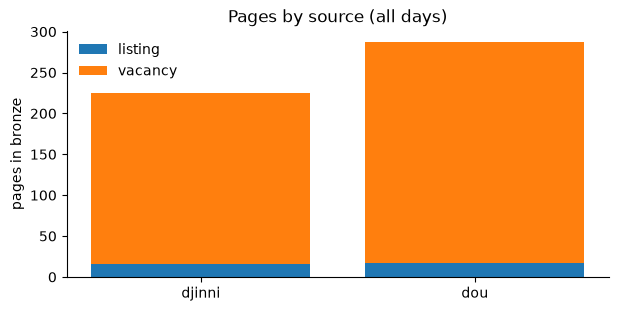

In [4]:
rows = con.execute("""
SELECT source, kind, count(*) FROM pages WHERE source IN ('dou', 'djinni') GROUP BY ALL
""").fetchall()
labels = sorted({r[0] for r in rows})
fig, ax = plt.subplots()
bottom = [0] * len(labels)
for kind in ("listing", "vacancy"):
    values = [next((r[2] for r in rows if r[0] == s and r[1] == kind), 0) for s in labels]
    ax.bar(labels, values, bottom=bottom, label=kind)
    bottom = [b + v for b, v in zip(bottom, values, strict=True)]
ax.set_ylabel("pages in bronze")
ax.set_title("Pages by source (all days)")
ax.legend(frameon=False)
plt.show()

## 2. Distinct vacancies

In [5]:
con.sql("""
SELECT source, count(DISTINCT url) AS distinct_vacancies, count(*) AS stored_copies
FROM pages WHERE kind = 'vacancy' GROUP BY source ORDER BY source
""").show()

┌─────────┬────────────────────┬───────────────┐
│ source  │ distinct_vacancies │ stored_copies │
│ varchar │       int64        │     int64     │
├─────────┼────────────────────┼───────────────┤
│ djinni  │                209 │           209 │
│ dou     │                270 │           270 │
└─────────┴────────────────────┴───────────────┘



## 3. Share of vacancies that state a salary

Latest stored copy of each vacancy page.

* **Djinni**: `baseSalary` in the `JobPosting` JSON-LD (declared by the employer). `estimatedSalary`
  is the site's own estimate and is *not* counted.
* **DOU**: a currency amount in the title or description text (regex, noisy by nature).

In [6]:
latest = con.execute("""
SELECT source, url, path FROM pages WHERE kind = 'vacancy'
QUALIFY row_number() OVER (PARTITION BY url ORDER BY dt DESC) = 1
""").fetchall()

DOU_SALARY = re.compile(
    r"(?:[$€₴]\s*\d{3,}|\d[\d\s.,]{2,}\s*(?:[$€₴]|usd|eur|uah|грн)\b|\b(?:usd|eur|uah|грн)\s*\d{3,})",
    re.IGNORECASE,
)


def djinni_base_salary(tree: LexborHTMLParser) -> dict | None:
    for node in tree.css('script[type="application/ld+json"]'):
        try:
            data = json.loads(node.text())
        except json.JSONDecodeError:
            continue
        for item in data if isinstance(data, list) else [data]:
            if isinstance(item, dict) and item.get("@type") == "JobPosting":
                return item.get("baseSalary")
    return None


def dou_salary_snippet(tree: LexborHTMLParser) -> str | None:
    parts = [
        n.text(separator=" ", strip=True) for n in tree.css("h1.g-h2, .b-typo.vacancy-section")
    ]
    match = DOU_SALARY.search(" ".join(parts))
    return match.group(0).strip() if match else None


stats = {"dou": [0, 0], "djinni": [0, 0]}  # [total, with salary]
samples = {"dou": [], "djinni": []}
for source, url, path in latest:
    if source not in stats:
        continue
    tree = LexborHTMLParser(Path(path).read_text(encoding="utf-8"))
    stats[source][0] += 1
    found = djinni_base_salary(tree) if source == "djinni" else dou_salary_snippet(tree)
    if found:
        stats[source][1] += 1
        if len(samples[source]) < 6:
            samples[source].append(
                (
                    url.rsplit("/", 2)[-2][:40],
                    found if isinstance(found, str) else json.dumps(found.get("value")),
                )
            )

for source, (total, with_salary) in stats.items():
    share = with_salary / total if total else 0
    print(f"{source:7s} {with_salary:4d} / {total:4d} vacancies  =  {share:5.1%}")

dou        6 /  270 vacancies  =   2.2%
djinni    17 /  209 vacancies  =   8.1%


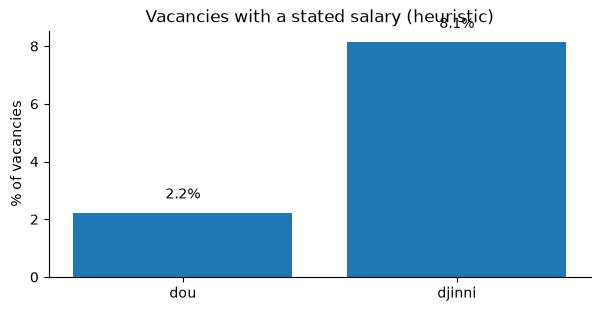

In [7]:
fig, ax = plt.subplots()
names = list(stats)
shares = [stats[s][1] / stats[s][0] * 100 if stats[s][0] else 0 for s in names]
ax.bar(names, shares)
for i, share in enumerate(shares):
    ax.text(i, share + 0.5, f"{share:.1f}%", ha="center")
ax.set_ylabel("% of vacancies")
ax.set_title("Vacancies with a stated salary (heuristic)")
plt.show()

In [8]:
# Eyeball the matches: heuristics on raw HTML need a sanity check.
for source, items in samples.items():
    print(source)
    for slug, found in items:
        print("   ", slug.ljust(42), "->", found)

dou
    364242                                     -> UAH 500
    379151                                     -> $500
    378850                                     -> $1000
    366014                                     -> $2000
    378060                                     -> $150
    363404                                     -> 150 000 грн
djinni
    857063-devops-engineer                     -> {"@type": "QuantitativeValue", "maxValue": 1800, "minValue": 1700, "unitText": "MONTH", "validFrom": "2026-11-06T15:47:45.596975", "validThrough": "2026-12-06T15:47:45.596975"}
    851289-senior-net-c-software-engineer-wi   -> {"@type": "QuantitativeValue", "maxValue": 6500, "minValue": 6000, "unitText": "MONTH", "validFrom": "2026-11-02T13:26:53.077373", "validThrough": "2026-12-02T13:26:53.077373"}
    855699-php-backend-developer-middle-seni   -> {"@type": "QuantitativeValue", "maxValue": 3300, "minValue": 3000, "unitText": "MONTH", "validFrom": "2026-10-28T19:45:04.336798", "validThroug

## 4. Findings (snapshot of 2026-11-06, one day of data)

* **Ingestion works end to end:** every stored page has HTTP 200, no errors.
  209 distinct Djinni and 270 DOU vacancies from the first listing page of each category.
* **Salary coverage is far below the plan's assumption.** Djinni states a salary in 17 of 209
  vacancies (8%), not the planned 40-60%. DOU is 6 of 270 (2%), in line with the planned ~10% at best.
  Both Djinni signals (JSON-LD and visible header) agree, so this is not a parsing artefact.
* **Caveats:** the sample is only the first listing page per category (newest/pinned vacancies),
  and the DOU regex is noisy (`$500` may be a bonus). Re-check after the first full crawl.
* **Consequence for later phases:** `fct_salary_by_skill` requires n >= 15 per cell and the salary
  model trains on vacancies with a range. With ~8% coverage that is a few hundred rows, so the
  DOU salary surveys (34 waves, thousands of rows) matter more than planned.